# Universidad del Valle de Guatemala
## CC3084 - Data Science
### Laboratorio 1 — Series de Tiempo

#### Cristian Tunchez - 231359  
#### Nadissa Vela - 23764

## Preparación de datos: partición entrenamiento/prueba y construcción de series mensuales

**Ejercicios 2 y 3.** Este notebook parte del conjunto de datos crudo, 
repite la preparación mínima ya validada en `01_analisis_exploratorio.ipynb`, 
divide el período de estudio en entrenamiento (70%) y prueba (30%) de forma 
**cronológica** (no aleatoria), y construye las series mensuales que se
analizarán en los notebooks 03–05.

El resultado de este notebook se guarda como un archivo nuevo en `data/processed/series_mensuales.csv`.


## Configuración del entorno

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display

pd.set_option("display.max_columns", 40)
MILES = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")
print("Librerías cargadas correctamente.")


Librerías cargadas correctamente.


## Carga y preparación mínima

Se repiten aquí solo los pasos de tipado y la vista consistente
`Turista + Excursionista`, ya justificados y documentados en
`01_analisis_exploratorio.ipynb` (sección 2 y conclusiones).

In [2]:
RUTA = "../data/raw/Base_Migracion_2009-2026jun.xlsx"
df = pd.read_excel(RUTA, sheet_name="Datos")

df["Año"]     = pd.to_numeric(df["Año"], errors="coerce")
df["Mes cod"] = pd.to_numeric(df["Mes cod"], errors="coerce")
df["Viajero"] = pd.to_numeric(df["Viajero"], errors="coerce")
df["fecha"]   = pd.to_datetime(dict(year=df["Año"], month=df["Mes cod"], day=1))
df["Pais_norm"] = df["País"].str.strip().str.title()

CONSISTENTES = ["Turista", "Excursionista"]
vis = df[df["Tipo de Viajero"].isin(CONSISTENTES)].copy()

print(f"Filas totales: {len(df):,}   |   Vista Turista+Excursionista: {len(vis):,}")
print(f"Periodo: {df['fecha'].min():%Y-%m} a {df['fecha'].max():%Y-%m}")


Filas totales: 161,036   |   Vista Turista+Excursionista: 137,642
Periodo: 2009-01 a 2026-06


## Ejercicio 2. Partición entrenamiento / prueba 

El 70%/30% se calcula sobre los **meses** del período de estudio, no sobre el 
número de filas del formato largo, el número de filas por mes no es constante 
porque desde 2023 se reportan más categorías de mercado por mes, así que un corte
"70% de filas" recortaría el período de entrenamiento a solo ~56% de los meses, 
lo cual no es lo que pide el enunciado.


In [3]:
meses = pd.DatetimeIndex(sorted(df["fecha"].unique()))
n_meses = len(meses)
corte_idx = int(round(n_meses * 0.70))
FECHA_CORTE = meses[corte_idx - 1]          # último mes de entrenamiento
FECHA_INICIO_TEST = meses[corte_idx]        # primer mes de prueba

print(f"Meses totales: {n_meses}")
print(f"Entrenamiento: {meses[0]:%Y-%m} -> {FECHA_CORTE:%Y-%m}  ({corte_idx} meses, "
      f"{corte_idx/n_meses*100:.1f}%)")
print(f"Prueba:        {FECHA_INICIO_TEST:%Y-%m} -> {meses[-1]:%Y-%m}  "
      f"({n_meses-corte_idx} meses, {(n_meses-corte_idx)/n_meses*100:.1f}%)")

# Nota: el corte cae justo antes de la reapertura post-pandemia, así que el
# conjunto de prueba incluye la recuperación 2021-2022, el cambio de
# metodología 2022->2023 y el año parcial 2026 -- todos ellos ya documentados
# como rupturas estructurales en el EDA.


Meses totales: 210
Entrenamiento: 2009-01 -> 2021-03  (147 meses, 70.0%)
Prueba:        2021-04 -> 2026-06  (63 meses, 30.0%)


## Ejercicio 3. Construcción de series mensuales 

**Serie obligatoria (3.a):** total mensual de viajeros internacionales. Se usa
la vista **Turista + Excursionista**, la única categoría consistente en todo
el período (ver nota del enunciado y sección de conclusiones del EDA); el total
"todos los tipos" tiene una ruptura de definición en 2022→2023 que distorsiona
cualquier serie continua.

**Categorías candidatas para 3.b:** antes de elegir, se valida la
**cobertura temporal completa** de cada categoría candidata sobre la vista
consistente (Turista+Excursionista) — no basta con que la variable no tenga
nulos, hace falta que cada valor tenga un registro en **todos los 210 meses**
del período, o la serie mensual quedaría con huecos estructurales que ARIMA
no puede manejar directamente.

In [4]:
def cobertura_mensual(data, columna, valor, meses_completos):
    sub = data[data[columna] == valor]
    meses_cubiertos = sub["fecha"].nunique()
    faltantes = meses_completos.difference(sub["fecha"].unique())
    return meses_cubiertos, faltantes

MESES_COMPLETOS = pd.date_range(df["fecha"].min(), df["fecha"].max(), freq="MS")

print("Verificación de cobertura -- Vías de ingreso (candidata 3.b.iii):")
for via in ["Aérea", "Terrestre", "Marítima"]:
    cubiertos, faltan = cobertura_mensual(vis, "Vía", via, MESES_COMPLETOS)
    print(f"  {via:12s}: {cubiertos}/{len(MESES_COMPLETOS)} meses con dato"
          + (f"  -> FALTAN {len(faltan)} meses, desde {faltan.min():%Y-%m}" if len(faltan) else "  -> OK"))


Verificación de cobertura -- Vías de ingreso (candidata 3.b.iii):
  Aérea       : 210/210 meses con dato  -> OK
  Terrestre   : 210/210 meses con dato  -> OK
  Marítima    : 96/210 meses con dato  -> FALTAN 114 meses, desde 2017-01


**Hallazgo de calidad de datos:** la vía **Marítima** solo tiene registros
de Turista+Excursionista hasta **diciembre de 2016**; a partir de **enero de
2017 faltan 114 meses consecutivos** (no son huecos aleatorios, es un corte
estructural — coherente con la nota ya documentada en el EDA: *"la vía
Marítima... pierde detalle a partir de 2017"*). No sabemos si el fenómeno
desapareció o si dejó de reportarse en esa granularidad, así que **no es
correcto imputar ceros** para esos 114 meses. Por esta razón se **descarta la
categoría Vías de ingreso** para el modelado de series de tiempo (aunque sí
se usó en el EDA a nivel agregado, donde la falta de detalle reciente no
afecta el total histórico) y se reemplaza por **Fronteras** (3.b.iv), que si
tiene cobertura completa.

In [5]:
print("Verificación de cobertura -- Fronteras (candidata 3.b.iv, top 3 por acumulado):")
top_front_chk = vis.groupby("Frontera")["Viajero"].sum().sort_values(ascending=False).head(3)
for front in top_front_chk.index:
    cubiertos, faltan = cobertura_mensual(vis, "Frontera", front, MESES_COMPLETOS)
    print(f"  {front:20s}: {cubiertos}/{len(MESES_COMPLETOS)} meses con dato"
          + (f"  -> FALTAN {len(faltan)} meses" if len(faltan) else "  -> OK"))

print("\nVerificación de cobertura -- Región dos (candidata 3.b.ii, top 3 por acumulado):")
EXCL = ["Cruceristas", "Cruceros", "0"]
top_reg_chk = (vis[~vis["Región dos"].isin(EXCL)]
               .groupby("Región dos")["Viajero"].sum().sort_values(ascending=False).head(3))
for reg in top_reg_chk.index:
    cubiertos, faltan = cobertura_mensual(vis, "Región dos", reg, MESES_COMPLETOS)
    print(f"  {reg:20s}: {cubiertos}/{len(MESES_COMPLETOS)} meses con dato"
          + (f"  -> FALTAN {len(faltan)} meses" if len(faltan) else "  -> OK"))


Verificación de cobertura -- Fronteras (candidata 3.b.iv, top 3 por acumulado):
  01 La Aurora        : 210/210 meses con dato  -> OK
  07 Valle Nuevo      : 210/210 meses con dato  -> OK
  09 San Cristóbal    : 210/210 meses con dato  -> OK

Verificación de cobertura -- Región dos (candidata 3.b.ii, top 3 por acumulado):
  América Del Centro  : 210/210 meses con dato  -> OK
  América Del Norte   : 205/210 meses con dato  -> FALTAN 5 meses
  Europa              : 205/210 meses con dato  -> FALTAN 5 meses


**Categorías seleccionadas (3.b):** con cobertura verificada, se eligen
**Regiones geográficas** (3.b.ii, variable `Región dos`) y **Fronteras**
(3.b.iv). Se descarta *Países de residencia* (3.b.i) por la ruptura de
granularidad de `País` en 2023 (documentada en el EDA), y *Vías de ingreso*
(3.b.iii) por el corte de cobertura de Marítima recién encontrado.

`Frontera` no tiene ningún hueco en las 3 series top. `Región dos`, en
cambio, muestra **5 meses sin ningún registro en América del Norte y en
Europa** — se investigan a continuación antes de decidir cómo tratarlos.

In [6]:
faltantes_norte = MESES_COMPLETOS.difference(vis.loc[vis["Región dos"] == "América Del Norte", "fecha"])
faltantes_europa = MESES_COMPLETOS.difference(vis.loc[vis["Región dos"] == "Europa", "fecha"])
print("Meses sin registro -- América del Norte:", [f"{m:%Y-%m}" for m in faltantes_norte])
print("Meses sin registro -- Europa:            ", [f"{m:%Y-%m}" for m in faltantes_europa])


Meses sin registro -- América del Norte: ['2020-04', '2020-05', '2020-06', '2020-07', '2020-08']
Meses sin registro -- Europa:             ['2020-04', '2020-05', '2020-06', '2020-07', '2020-08']


**Diagnóstico:** los 5 meses sin registro en ambas regiones son
**exactamente abril-agosto de 2020**, el cierre total de fronteras
internacionales por la pandemia (ya documentado en el EDA: el mínimo mensual
absoluto de toda la serie es mayo-2020). No es un vacío de captura de datos
como el de Marítima (que empieza en 2017 y nunca se recupera): aquí
simplemente **no hubo ningún viajero de esa región** ese mes porque la
frontera estuvo cerrada, así que la fila no existe en el Excel. La limpieza
correcta es **imputar 0** únicamente en ese rango ya documentado como cierre
total (no como regla general para cualquier hueco futuro, que seguiría
tratándose como el de Marítima).

In [7]:
VENTANA_CIERRE_TOTAL = pd.date_range("2020-03-01", "2021-06-01", freq="MS")

def serie_mensual(data: pd.DataFrame, filtro=None) -> pd.Series:
    # Agrega Viajero por mes calendario y devuelve una Serie con freq mensual (MS).
    d = data if filtro is None else data[filtro]
    s = d.groupby("fecha")["Viajero"].sum().sort_index()
    s = s.asfreq("MS")  # fuerza frecuencia mensual explícita
    huecos = s[s.isna()].index
    huecos_cierre = huecos.intersection(VENTANA_CIERRE_TOTAL)
    huecos_otros = huecos.difference(VENTANA_CIERRE_TOTAL)
    if len(huecos_cierre):
        s.loc[huecos_cierre] = 0.0  # cierre total de fronteras: 0 viajeros reales, no dato faltante
    if len(huecos_otros):
        print(f"  AVISO: quedan {len(huecos_otros)} meses sin dato fuera de la ventana de cierre "
              f"({huecos_otros.min():%Y-%m} ...) -- revisar antes de usar esta serie.")
    return s

series = {}

# 3.a Serie obligatoria
series["total"] = serie_mensual(vis)

# 3.b.ii Regiones geográficas: top 3 de 'Región dos' por total acumulado en todo el período
print("Top 3 regiones (Región dos) por total acumulado 2009-jun2026:")
display(top_reg_chk.round(0).to_frame("viajeros"))

MAPA_REGION = {"América Del Centro": "america_central",
               "América Del Norte": "america_norte",
               "Europa": "europa"}
for region in top_reg_chk.index:
    clave = "region_" + MAPA_REGION.get(region, region.lower().replace(" ", "_"))
    series[clave] = serie_mensual(vis, vis["Región dos"] == region)

# 3.b.iv Fronteras: top 3 por total acumulado
print("\nTop 3 fronteras por total acumulado 2009-jun2026:")
display(top_front_chk.round(0).to_frame("viajeros"))

MAPA_FRONTERA = {"01 La Aurora": "frontera_aurora",
                 "07 Valle Nuevo": "frontera_valle_nuevo",
                 "09 San Cristóbal": "frontera_san_cristobal"}
for front in top_front_chk.index:
    clave = MAPA_FRONTERA.get(front, "frontera_" + front[3:].lower().replace(" ", "_"))
    series[clave] = serie_mensual(vis, vis["Frontera"] == front)

print("\nSeries construidas:", list(series.keys()))


Top 3 regiones (Región dos) por total acumulado 2009-jun2026:


,viajeros
Región dos,
América Del Centro,33283932.0
América Del Norte,9160810.0
Europa,2149271.0



Top 3 fronteras por total acumulado 2009-jun2026:


,viajeros
Frontera,
01 La Aurora,18989985.0
07 Valle Nuevo,10143045.0
09 San Cristóbal,4183632.0



Series construidas: ['total', 'region_america_central', 'region_america_norte', 'region_europa', 'frontera_aurora', 'frontera_valle_nuevo', 'frontera_san_cristobal']


In [8]:
resumen = []
for nombre, s in series.items():
    resumen.append({
        "serie": nombre, "inicio": s.index.min().strftime("%Y-%m"),
        "fin": s.index.max().strftime("%Y-%m"), "frecuencia": "Mensual (MS)",
        "n_obs": len(s), "faltantes": int(s.isna().sum()), "total_acumulado": s.sum(),
    })
resumen = pd.DataFrame(resumen).sort_values("total_acumulado", ascending=False)
display(resumen.style.format({"total_acumulado": "{:,.0f}"}))


,serie,inicio,fin,frecuencia,n_obs,faltantes,total_acumulado
0,total,2009-01,2026-06,Mensual (MS),210,0,"46,711,913"
1,region_america_central,2009-01,2026-06,Mensual (MS),210,0,"33,283,932"
4,frontera_aurora,2009-01,2026-06,Mensual (MS),210,0,"18,989,985"
5,frontera_valle_nuevo,2009-01,2026-06,Mensual (MS),210,0,"10,143,045"
2,region_america_norte,2009-01,2026-06,Mensual (MS),210,0,"9,160,810"
6,frontera_san_cristobal,2009-01,2026-06,Mensual (MS),210,0,"4,183,632"
3,region_europa,2009-01,2026-06,Mensual (MS),210,0,"2,149,271"


**Verificación:** todas las series cubren el mismo rango (2009-01 a
2026-06, 210 observaciones mensuales) y no tienen huecos — el `groupby` sobre
`fecha` con `asfreq("MS")` no introdujo ningún `NaN`, confirmando que el
dataset original no tiene meses faltantes para ninguna de las categorías
elegidas.

## Vista rápida de las series construidas

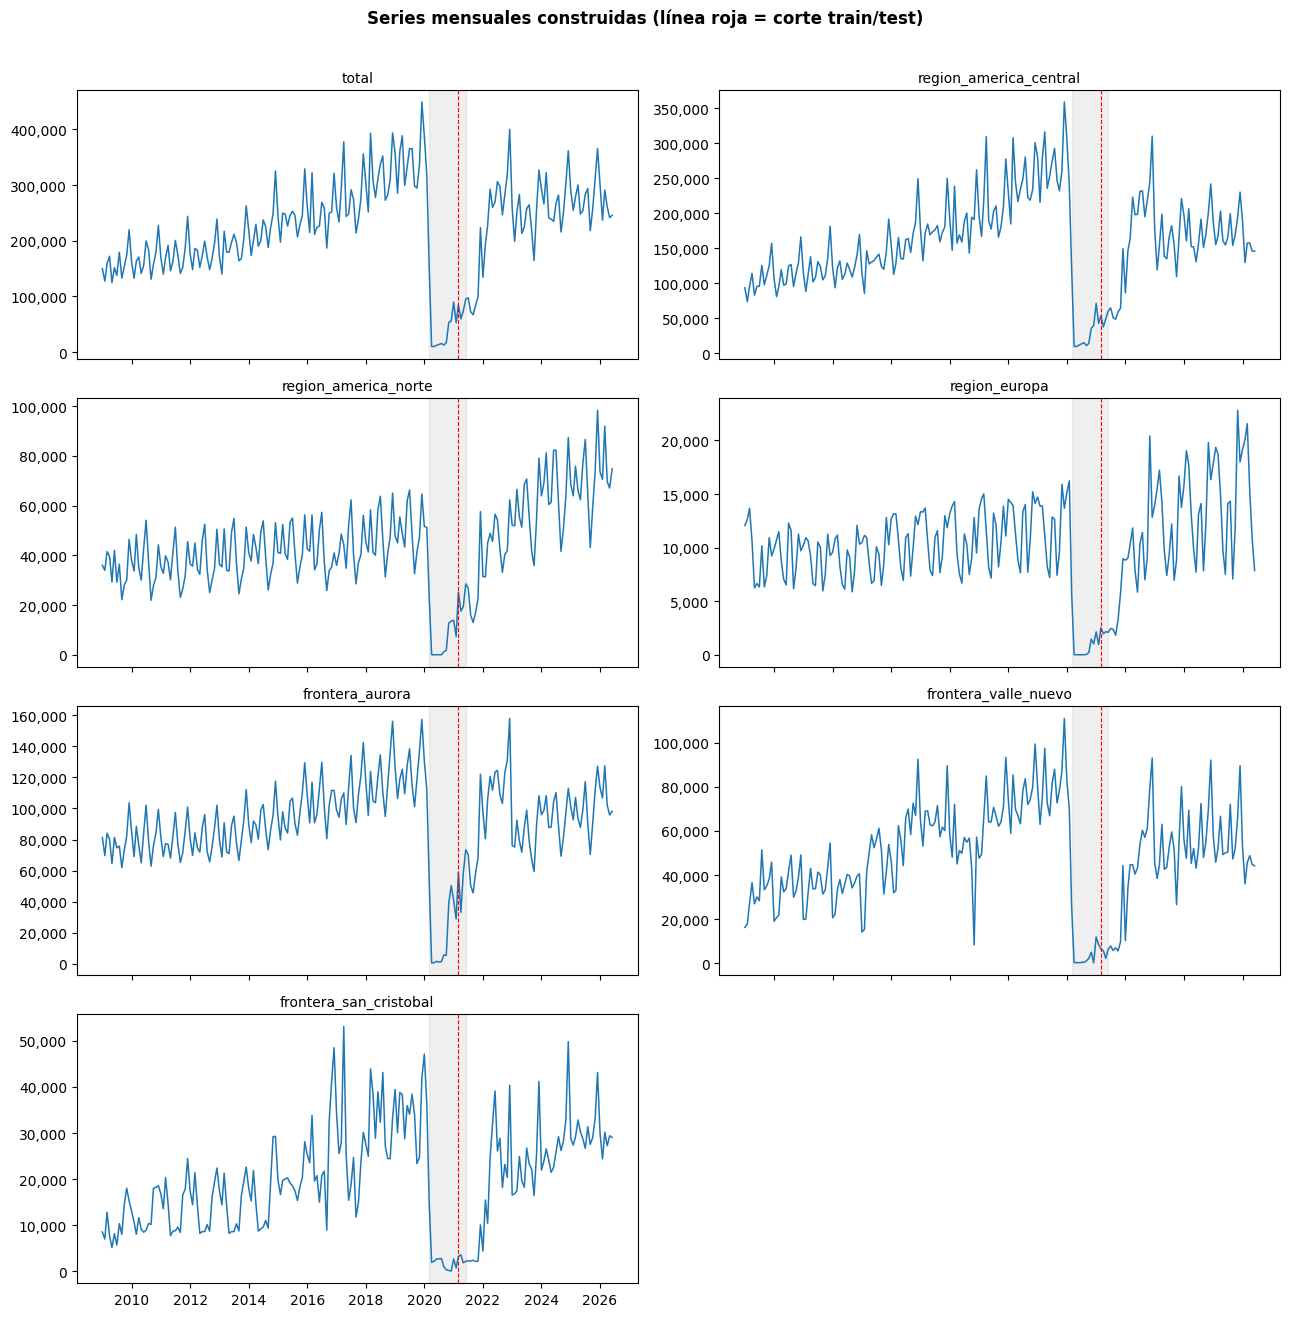

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(13, 13), sharex=True)
axes = axes.ravel()
for ax, (nombre, s) in zip(axes, series.items()):
    ax.plot(s.index, s.values, lw=1.1, color="C0")
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-06-01"), color="grey", alpha=0.12)
    ax.axvline(FECHA_CORTE, color="red", ls="--", lw=0.8)
    ax.set_title(nombre, fontsize=10)
    ax.yaxis.set_major_formatter(MILES)
axes[-1].axis("off")
fig.suptitle("Series mensuales construidas (línea roja = corte train/test)", y=1.01, fontweight="bold")
plt.tight_layout()
plt.show()


**Lectura rápida:** todas las series comparten la misma forma general
(crecimiento 2009–2019, colapso pandémico, recuperación posterior) porque son
subconjuntos aditivos del mismo fenómeno migratorio, pero difieren en escala,
en la fecha de recuperación y en la fuerza de la estacionalidad — precisamente
lo que se cuantificará en los notebooks 03–05 y se comparará en el 06.

## Exportación a `data/processed/` 

Se guarda un único CSV en formato **largo/tidy** (una fila por observación:
`serie`, `fecha`, `conjunto`, `viajeros`) para que los notebooks de modelado
filtren la serie y el conjunto (`train`/`test`) que necesiten. Los datos
crudos (`data/raw/`) no se tocan en ningún momento.

In [10]:
filas = []
for nombre, s in series.items():
    conjunto = np.where(s.index <= FECHA_CORTE, "train", "test")
    filas.append(pd.DataFrame({"serie": nombre, "fecha": s.index,
                                "conjunto": conjunto, "viajeros": s.values}))
panel = pd.concat(filas, ignore_index=True)

RUTA_SALIDA = "../data/processed/series_mensuales.csv"
panel.to_csv(RUTA_SALIDA, index=False)

print(f"Guardado: {RUTA_SALIDA}  ({len(panel):,} filas, {panel['serie'].nunique()} series)")
display(panel.groupby(["serie", "conjunto"]).size().unstack())


Guardado: ../data/processed/series_mensuales.csv  (1,470 filas, 7 series)


conjunto,test,train
serie,,
frontera_aurora,63,147
frontera_san_cristobal,63,147
frontera_valle_nuevo,63,147
region_america_central,63,147
region_america_norte,63,147
region_europa,63,147
total,63,147


## 6. Conclusiones

1. La partición entrenamiento/prueba se hizo **cronológicamente** por meses
   (no por filas ni de forma aleatoria): **147 meses (70%)** de entrenamiento
   (2009-01 a 2021-03) y **63 meses (30%)** de prueba (2021-04 a 2026-06).
2. Se construyeron **7 series mensuales**: el total obligatorio
   (Turista+Excursionista) y dos categorías completas de 3 series cada una
   (Regiones geográficas y Fronteras, ambas top-3 por total acumulado),
   evitando *País* por su ruptura de granularidad en 2023 y *Vías de ingreso*
   por el corte de cobertura de Marítima (sin datos desde 2017) detectado en
   este mismo notebook.
3. Ninguna de las 7 series construidas tiene valores faltantes; todas
   comparten el rango 2009-01 a 2026-06 con frecuencia mensual (`MS`).
4. El resultado se guardó en `data/processed/series_mensuales.csv`, dejando
   `data/raw/` intacto, listo para los análisis de series de tiempo
   (notebooks `03_serie_total.ipynb`, `04_series_regiones.ipynb`,
   `05_series_fronteras.ipynb`).
